***Part 1. Image Classification***


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
folder_path = '/content/drive/MyDrive/Lab2_Computational_Intelligence'

In [ ]:
part1_path = folder_path + '/Part1_Classification'
for folder in ['dataset', 'models']:
    os.makedirs(part1_path + '/' + folder, exist_ok=True)


In [ ]:
dataset_path = part1_path + '/dataset'

for name in ['duck', 'bottle', 'cola_can']:
    os.makedirs(dataset_path + '/' + name, exist_ok=True)

***1.1 Dataset Verification***

In [ ]:
import os
dataset_path = part1_path + '/dataset'
classes = ['duck', 'bottle', 'cola_can']

for name in classes:
    images = os.listdir(dataset_path + '/' + name)
    print(name, ':', len(images), 'files')

duck : 54 files
bottle : 51 files
cola_can : 52 files


***Present 5 pictures of each class***

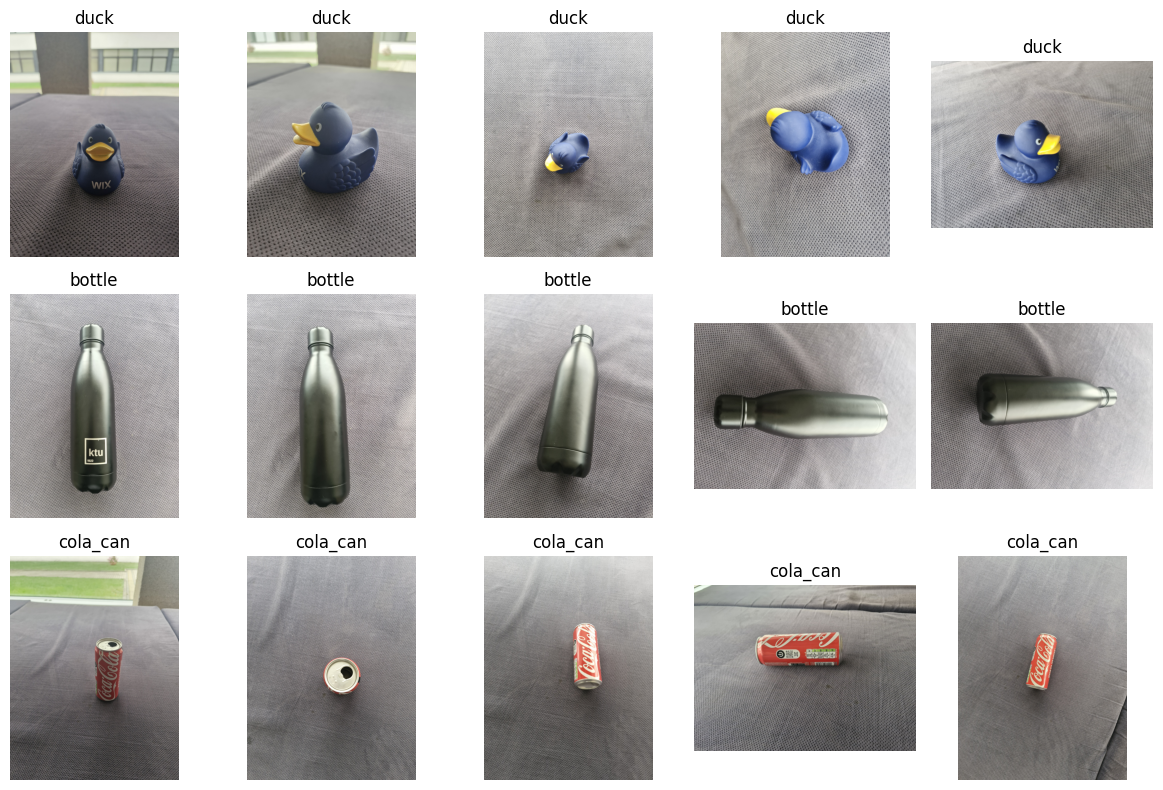

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

for i, name in enumerate(classes):
    files = os.listdir(dataset_path + '/' + name)

    for j in range(5):
        img = Image.open(dataset_path + '/' + name + '/' + files[j])

        plt.subplot(3, 5, i * 5 + j + 1)
        plt.imshow(img)
        plt.title(name)
        plt.axis('off')

plt.tight_layout()
plt.show()

***Split the images***

In [ ]:
import random
import shutil

random.seed(42)

split_path = part1_path + '/split_dataset'

for name in classes:
    files = os.listdir(dataset_path + '/' + name)
    files = sorted([f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))])

    random.shuffle(files)
    files = files[:50]

    if len(files) < 50:
        raise ValueError(name + ' has fewer than 50 images')

    splits = {
        'train': files[:35],
        'val': files[35:42],
        'test': files[42:50]
    }

    for split, images in splits.items():
        folder = split_path + '/' + split + '/' + name
        os.makedirs(folder, exist_ok=True)

        for img in images:
            shutil.copy2(dataset_path + '/' + name + '/' + img, folder + '/' + img)


***Check the results***

In [ ]:
for split in ['train', 'val', 'test']:
    print(split)

    for name in classes:
        folder = split_path + '/' + split + '/' + name
        print(name, len(os.listdir(folder)))

train
duck 35
bottle 35
cola_can 35
val
duck 7
bottle 7
cola_can 7
test
duck 8
bottle 8
cola_can 8


***Image Preprocessing and Data Loading***

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [ ]:
train_data = datasets.ImageFolder(split_path + '/train', transform=transform)
val_data = datasets.ImageFolder(split_path + '/val', transform=transform)
test_data = datasets.ImageFolder(split_path + '/test', transform=transform)

print("Classes:", train_data.classes)
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Classes: ['bottle', 'cola_can', 'duck']
Training: 105
Validation: 21
Testing: 24


In [ ]:
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader = DataLoader(val_data, batch_size=16)
test_loader = DataLoader(test_data, batch_size=16)

***Model Implementation and Training***

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = models.mobilenet_v3_small(weights='DEFAULT')

model.classifier[3] = nn.Linear(
    model.classifier[3].in_features, 3
)

model = model.to(device)

print("Using:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 134MB/s]


Using: cuda


***Define the loss function and optimizer***

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

train_losses = []
val_losses = []

***Train the model***

In [ ]:
epochs = 10
best_loss = float('inf')

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_data)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_data)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}/{epochs} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")

    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), part1_path + '/models/best_model.pth')


Epoch 1/10 | Train: 1.0871 | Val: 0.9227
Epoch 2/10 | Train: 0.7845 | Val: 0.6881
Epoch 3/10 | Train: 0.6275 | Val: 0.5103
Epoch 4/10 | Train: 0.4410 | Val: 0.3790
Epoch 5/10 | Train: 0.3125 | Val: 0.2856
Epoch 6/10 | Train: 0.2348 | Val: 0.2225
Epoch 7/10 | Train: 0.1537 | Val: 0.1866
Epoch 8/10 | Train: 0.1160 | Val: 0.1550
Epoch 9/10 | Train: 0.0901 | Val: 0.1284
Epoch 10/10 | Train: 0.0826 | Val: 0.1130


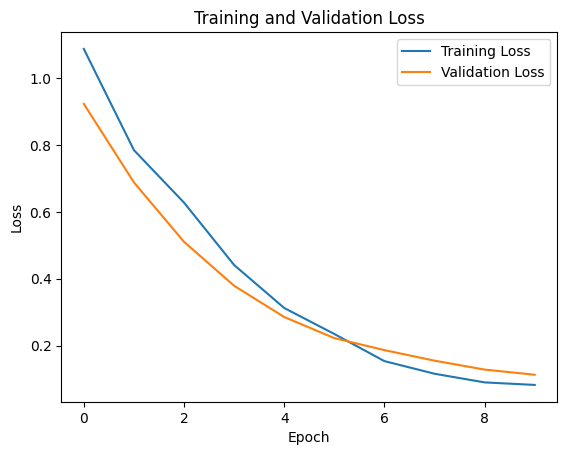

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

***Model Evaluation***

***Calculate test accuracy***

In [ ]:
from sklearn.metrics import accuracy_score

# Load the best saved model
model.load_state_dict(torch.load(
    part1_path + '/models/best_model.pth',
    map_location=device,
    weights_only=True
))

model.eval()

actual = []
predicted = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        actual.extend(labels.tolist())
        predicted.extend(predictions.cpu().tolist())

accuracy = accuracy_score(actual, predicted)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 91.67%


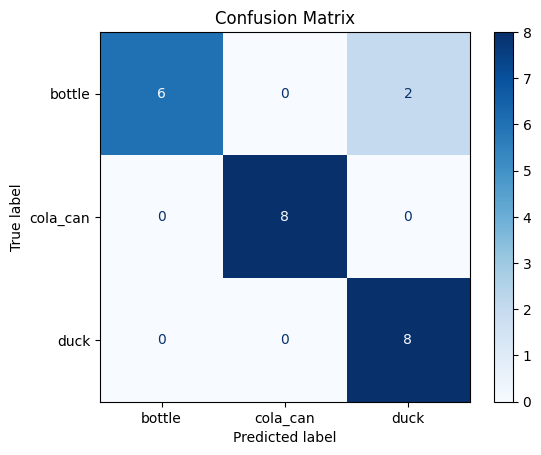

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    actual,
    predicted,
    labels=range(3),
    display_labels=test_data.classes,
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.show()

***SHOWING THE INCORRECT PICTRES***

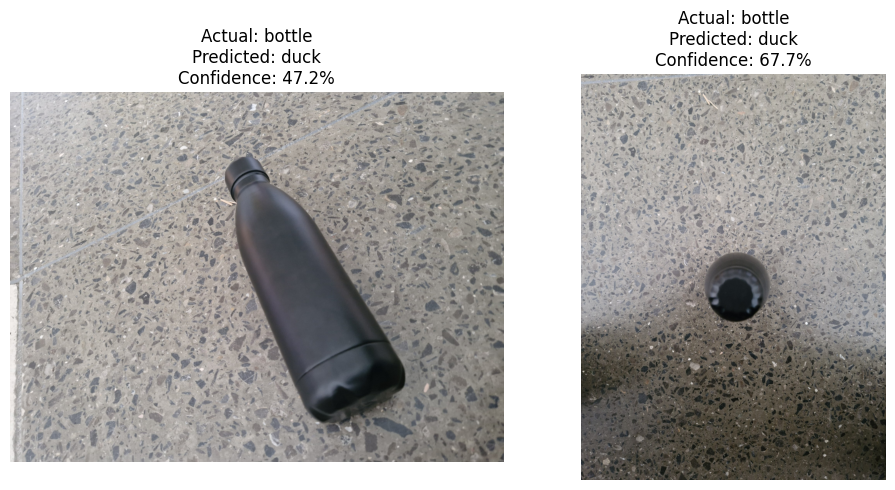

In [ ]:
wrong = [i for i in range(len(actual)) if actual[i] != predicted[i]]

plt.figure(figsize=(10, 5))

for j, i in enumerate(wrong):
    image = Image.open(test_data.samples[i][0]).convert('RGB')

    with torch.no_grad():
        tensor, _ = test_data[i]
        output = model(tensor.unsqueeze(0).to(device))
        confidence = torch.softmax(output, dim=1).max().item() * 100

    plt.subplot(1, len(wrong), j + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {test_data.classes[actual[i]]}\n"
        f"Predicted: {test_data.classes[predicted[i]]}\n"
        f"Confidence: {confidence:.1f}%"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

***Visualize Classification Results***

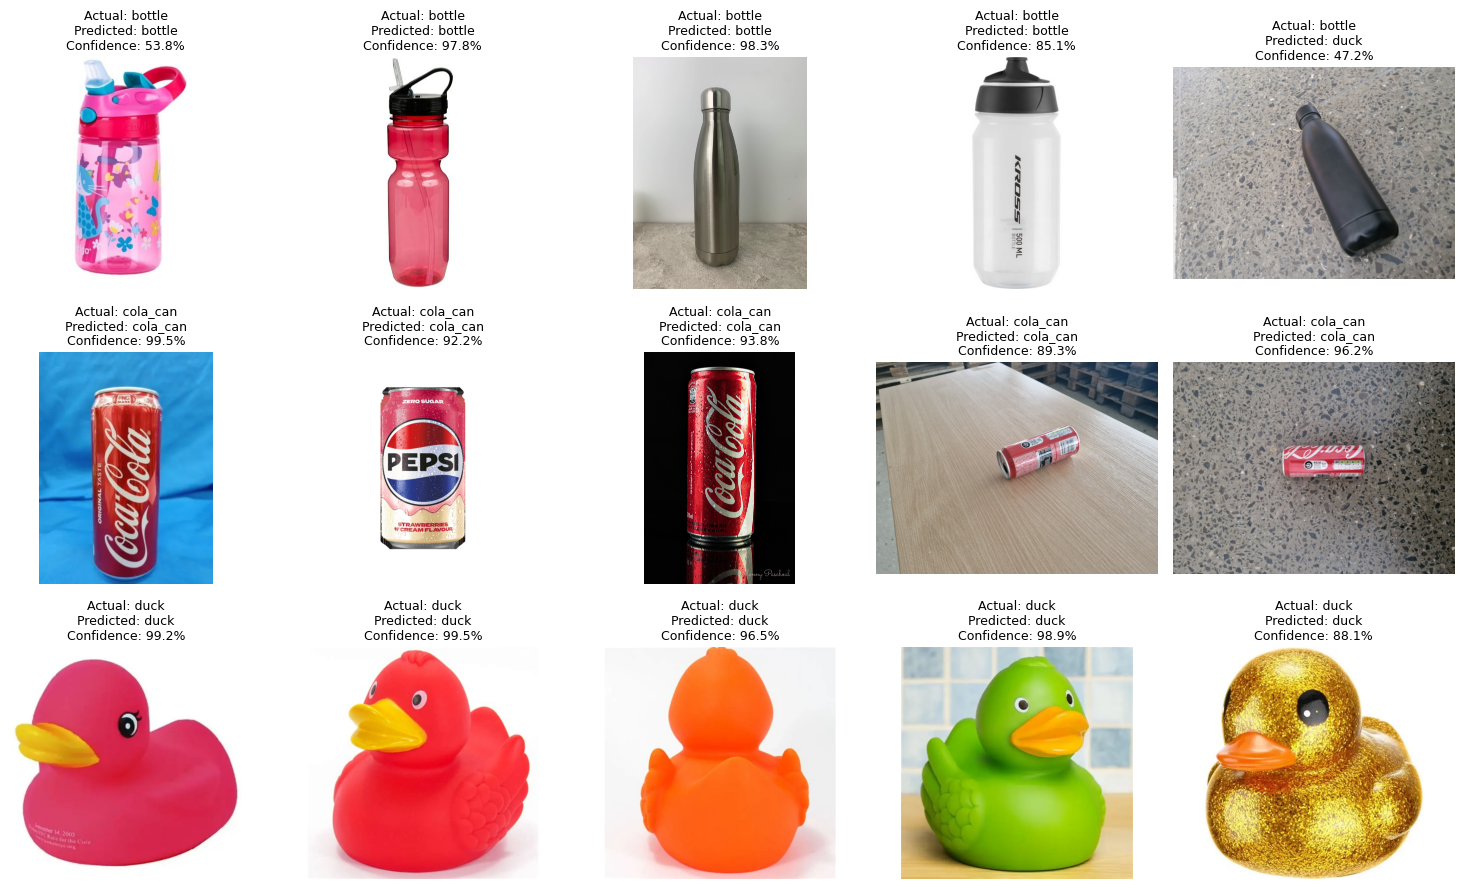

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, name in enumerate(test_data.classes):

    indices = [j for j, label in enumerate(test_data.targets) if label == i][:5]

    for k, index in enumerate(indices):
        image, actual_label = test_data[index]

        with torch.no_grad():
            output = model(image.unsqueeze(0).to(device))
            probabilities = torch.softmax(output, dim=1)
            confidence, prediction = probabilities.max(dim=1)

        original = Image.open(test_data.samples[index][0]).convert('RGB')

        axes[i, k].imshow(original)
        axes[i, k].set_title(
            f"Actual: {name}\n"
            f"Predicted: {test_data.classes[prediction.item()]}\n"
            f"Confidence: {confidence.item() * 100:.1f}%",
            fontsize=9
        )
        axes[i, k].axis('off')

plt.tight_layout()
plt.show()